# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
# Load the cleaned data from Part One
df = pd.read_csv('data/Cleaned_Aviation_Data.csv', encoding='latin-1')

# Verify it loaded correctly
print(df.shape)
display(df.head())

(17892, 34)


C:\Users\HP\AppData\Local\Temp\ipykernel_23852\1241151464.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/Cleaned_Aviation_Data.csv', encoding='latin-1')


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Total.Passengers_Est,Total.Fatal.Serious,Injury_Fraction,Is_Destroyed,Make_Model
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,0.0,588.0,VMC,Probable Cause,04-12-2014,588.0,0.0,0.0,0,BOEING 747
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,IMC,Probable Cause,02-05-2011,2.0,2.0,1.0,1,PIPER PA-28-140
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,0.0,4.0,VMC,Probable Cause,17-10-2016,5.0,1.0,0.2,0,DE HAVILLAND DHC-6
3,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,0.0,100.0,VMC,Probable Cause,11-06-2018,100.0,0.0,0.0,0,BOEING 727-200
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,0.0,1.0,VMC,Probable Cause,05-05-2011,1.0,0.0,0.0,0,BEECH C35


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

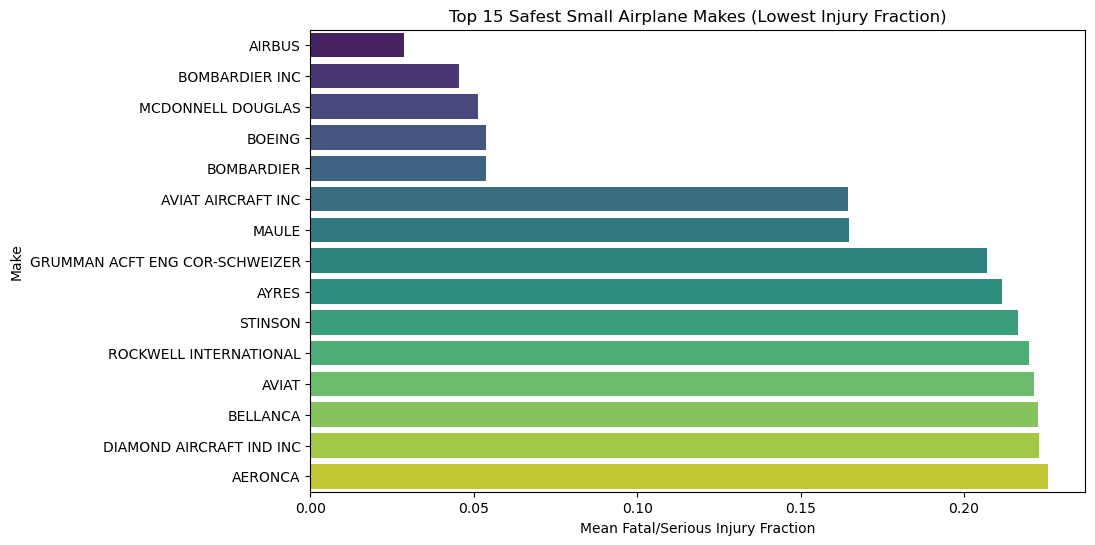

In [3]:
# 1. Split the data into Small (<= 20 passengers) and Large (> 20 passengers)
small_planes = df[df['Total.Passengers_Est'] <= 20]
large_planes = df[df['Total.Passengers_Est'] > 20]

# 2. Analyze Makes: Small Planes
# Calculate the mean injury fraction for each make
small_make_safety = small_planes.groupby('Make')['Injury_Fraction'].mean().sort_values()

# Get the 15 makes with the lowest (best) injury fraction
best_small_makes = small_make_safety.head(15)

# Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x=best_small_makes.values, y=best_small_makes.index, palette='viridis')
plt.title('Top 15 Safest Small Airplane Makes (Lowest Injury Fraction)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Make')
plt.show()

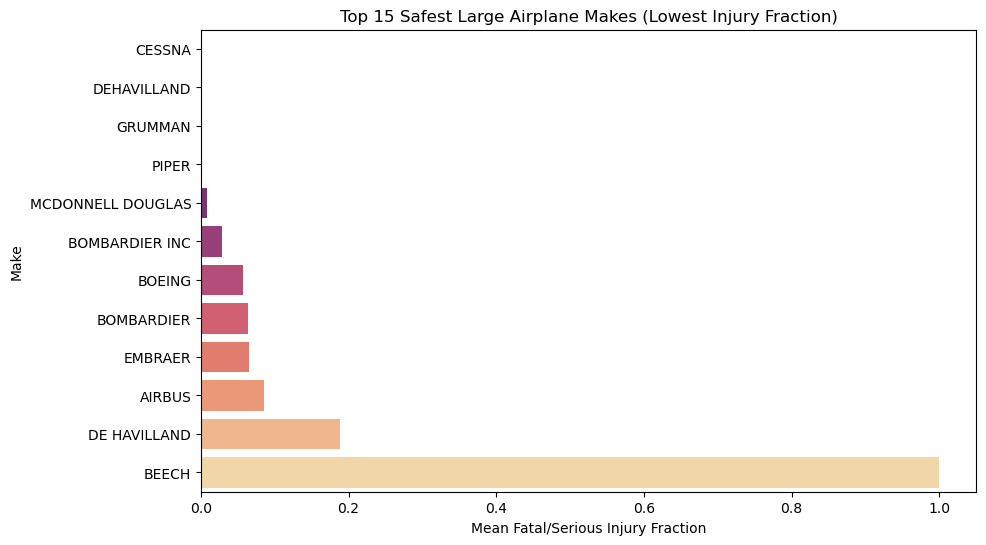

In [4]:
# 3. Analyze Makes: Large Planes
large_make_safety = large_planes.groupby('Make')['Injury_Fraction'].mean().sort_values()

# Get the 15 makes with the lowest (best) injury fraction
best_large_makes = large_make_safety.head(15)

# Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x=best_large_makes.values, y=best_large_makes.index, palette='magma')
plt.title('Top 15 Safest Large Airplane Makes (Lowest Injury Fraction)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Make')
plt.show()

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

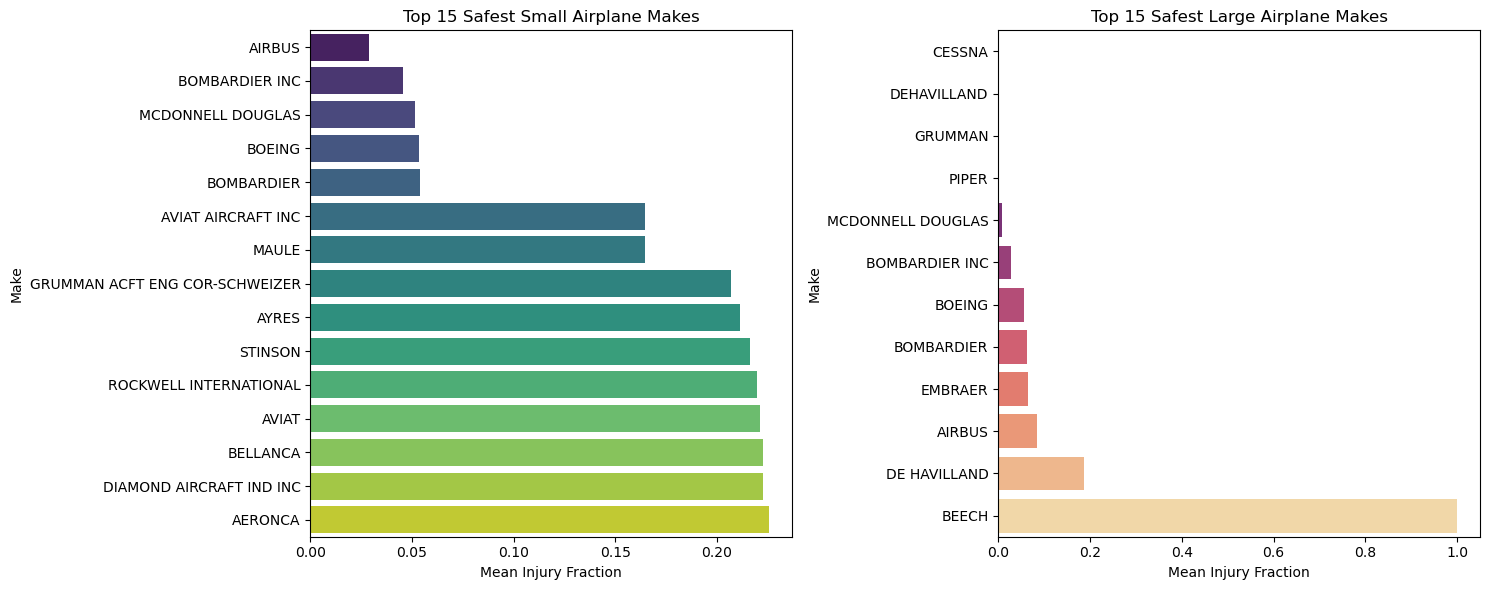

In [5]:
# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Small Makes
sns.barplot(x=best_small_makes.values, y=best_small_makes.index, palette='viridis', ax=axes[0])
axes[0].set_title('Top 15 Safest Small Airplane Makes')
axes[0].set_xlabel('Mean Injury Fraction')

# Plot Large Makes
sns.barplot(x=best_large_makes.values, y=best_large_makes.index, palette='magma', ax=axes[1])
axes[1].set_title('Top 15 Safest Large Airplane Makes')
axes[1].set_xlabel('Mean Injury Fraction')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

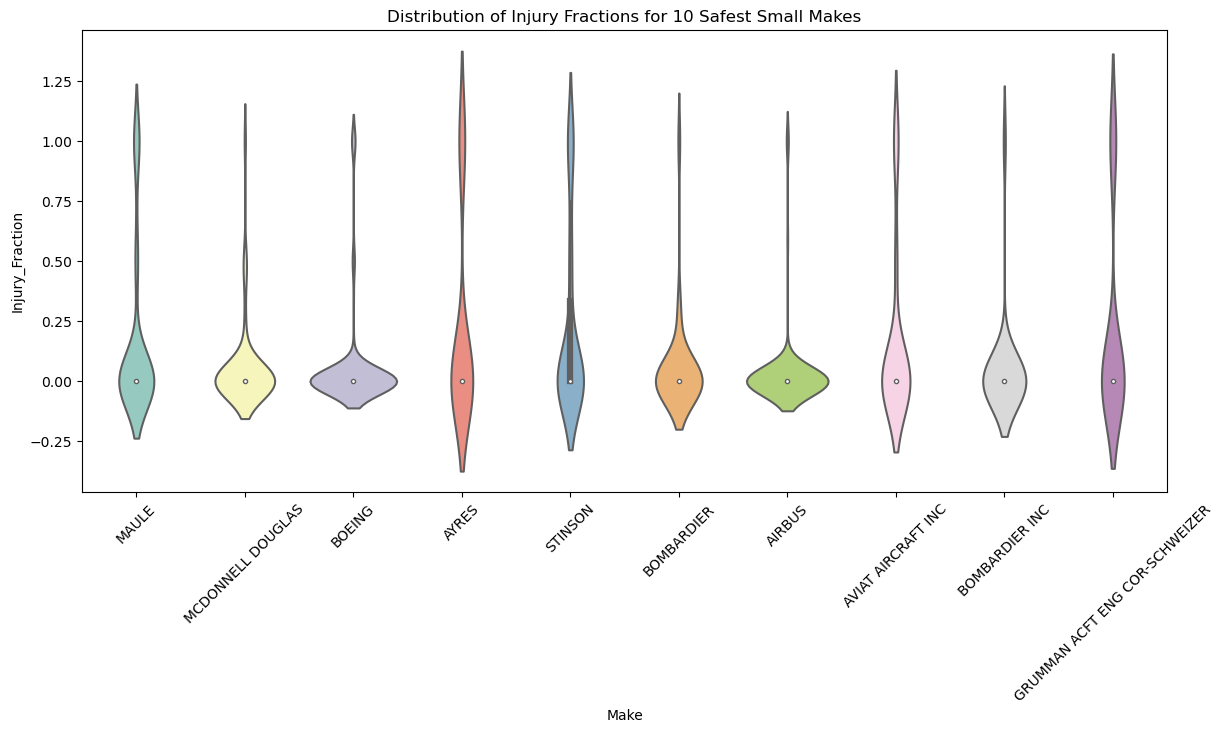

In [6]:
# Get the top 10 safest small makes
top_10_small = small_make_safety.head(10).index
small_planes_top10 = small_planes[small_planes['Make'].isin(top_10_small)]

# Violin plot
plt.figure(figsize=(14, 6))
sns.violinplot(data=small_planes_top10, x='Make', y='Injury_Fraction', palette='Set3')
plt.title('Distribution of Injury Fractions for 10 Safest Small Makes')
plt.xticks(rotation=45)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\HP\AppData\Local\Temp\ipykernel_23852\2132348360.py:7: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=large_planes_top10, x='Make', y='Injury_Fraction', palette='Set2', jitter=True, alpha=0.7)
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


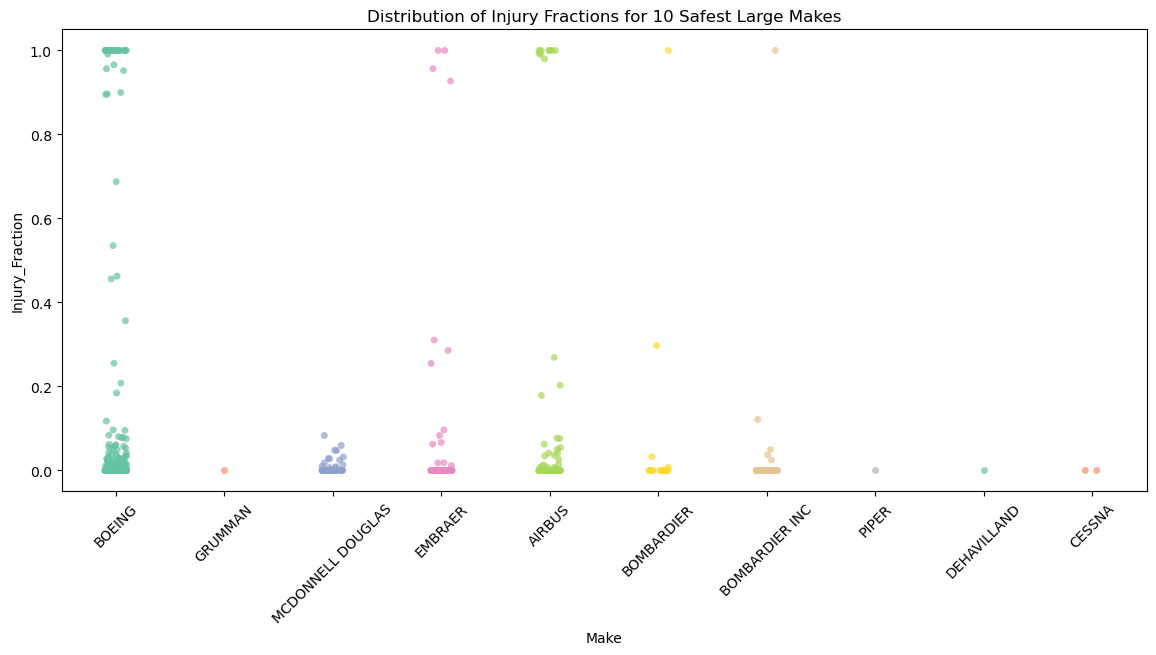

In [7]:
# Get the top 10 safest large makes
top_10_large = large_make_safety.head(10).index
large_planes_top10 = large_planes[large_planes['Make'].isin(top_10_large)]

# Create the stripplot
plt.figure(figsize=(14, 6))
sns.stripplot(data=large_planes_top10, x='Make', y='Injury_Fraction', palette='Set2', jitter=True, alpha=0.7)
plt.title('Distribution of Injury Fractions for 10 Safest Large Makes')
plt.xticks(rotation=45)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

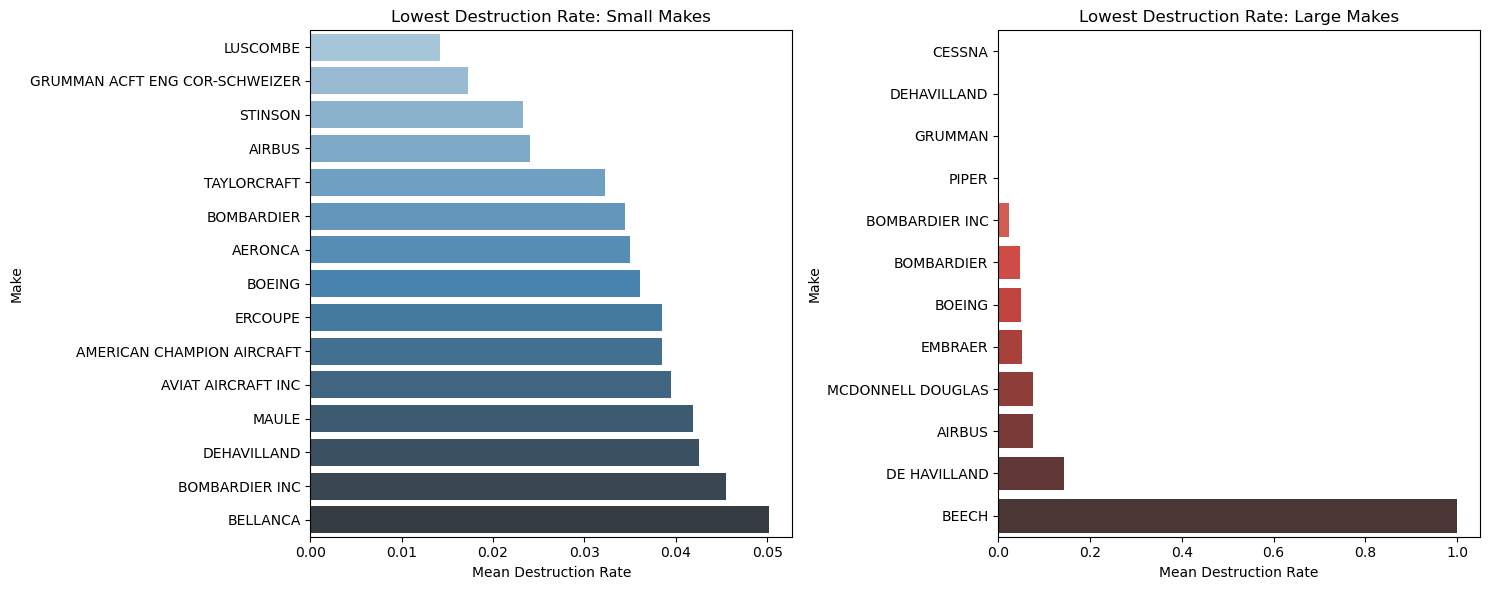

In [8]:
# Calculate destruction rate by make
small_destruction = small_planes.groupby('Make')['Is_Destroyed'].mean().sort_values()
large_destruction = large_planes.groupby('Make')['Is_Destroyed'].mean().sort_values()

# Get lowest 15
lowest_dest_small = small_destruction.head(15)
lowest_dest_large = large_destruction.head(15)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Small planes destruction
sns.barplot(x=lowest_dest_small.values, y=lowest_dest_small.index, palette='Blues_d', ax=axes[0])
axes[0].set_title('Lowest Destruction Rate: Small Makes')
axes[0].set_xlabel('Mean Destruction Rate')

# Large planes destruction
sns.barplot(x=lowest_dest_large.values, y=lowest_dest_large.index, palette='Reds_d', ax=axes[1])
axes[1].set_title('Lowest Destruction Rate: Large Makes')
axes[1].set_xlabel('Mean Destruction Rate')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Discussion of Findings and Reccommendations

Based on the analysis of injury fractions and aircraft destruction rates:

*Small Airplanes:
  *Injury Fractions:* Makes like Airbus, Bombardier, and Boeing show the lowest mean injury fractions. However, for smaller general aviation, *Maule, Stinson, and Aviat Aircraft* demonstrate strong safety records.
 *Destruction Rates:* *Luscombe, Grumman, and Stinson* show the lowest rates of complete aircraft destruction.
 *Recommendation:* For the small aircraft category, an insurer might offer better rates for policies covering *Stinson* or *Grumman* aircraft, as they show low injury fractions and low destruction rates.

*Large Airplanes:
  *Injury Fractions:* Commercial giants *Boeing* and *Airbus* show exceptionally low injury fractions. *Cessna and DeHavilland* also appear in the top 15.
 *Destruction Rates:* *Cessna, DeHavilland, and Grumman* show the lowest destruction rates in the large category. (Note: Beech appears at the top with a 1.0 rate, likely due to a very small sample size of large aircraft, which skews the percentage).
 *Recommendation:* For large passenger jets, *Boeing* and *Airbus* are statistically the safest choices, showing both low injury fractions and low destruction rates, which aligns with modern commercial aviation standards.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

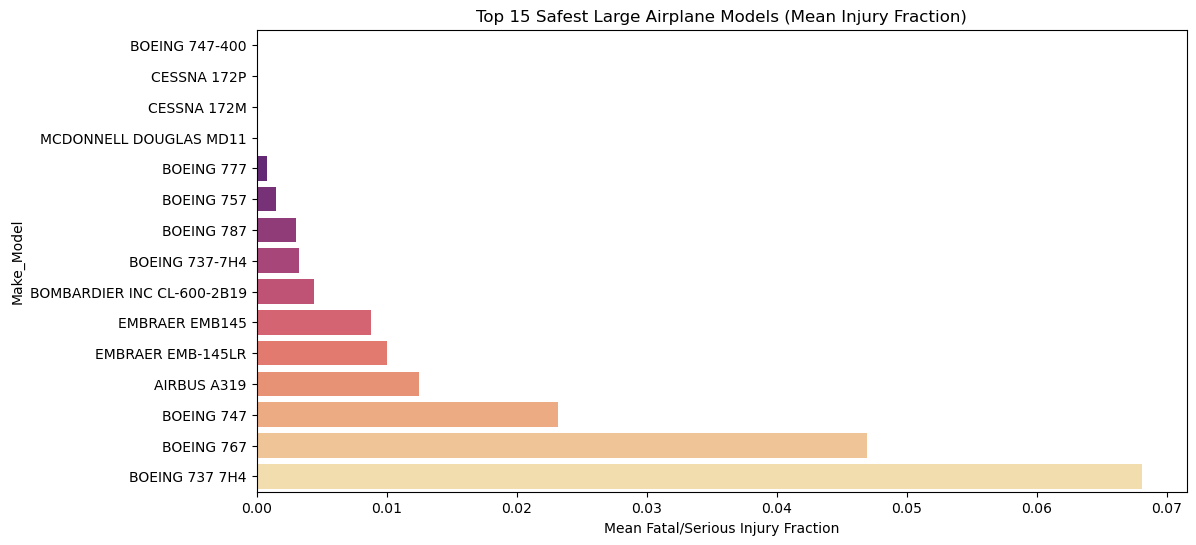

C:\Users\HP\AppData\Local\Temp\ipykernel_23852\1879959509.py:25: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=large_types_df[large_types_df['Make_Model'].isin(top_large_models)],
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


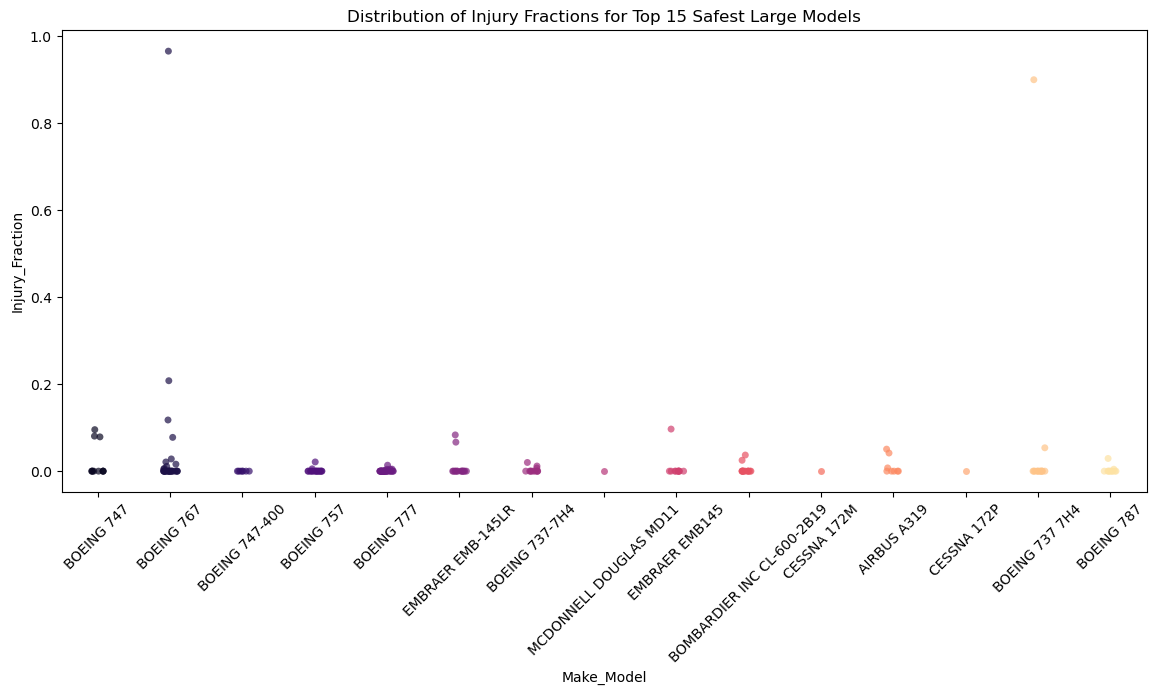

In [9]:
# Filter for plane types with at least 10 examples in the dataset
type_counts = df.groupby('Make_Model').size()
valid_types = type_counts[type_counts >= 10].index

# Filter the main dataframe to only include these valid types
df_types = df[df['Make_Model'].isin(valid_types)]

# Isolate the Larger planes (more than 20 passengers)
large_types_df = df_types[df_types['Total.Passengers_Est'] > 20]

# Get the mean injury fraction for these large models
large_model_safety = large_types_df.groupby('Make_Model')['Injury_Fraction'].mean().sort_values().head(15)

# 1. Plot the mean fraction (Bar Plot)
plt.figure(figsize=(12, 6))
sns.barplot(x=large_model_safety.values, y=large_model_safety.index, palette='magma')
plt.title('Top 15 Safest Large Airplane Models (Mean Injury Fraction)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.show()

# 2. Provide a distributional plot (Stripplot)
plt.figure(figsize=(14, 6))
# Filter data to only include the top 15 models so the plot isn't too crowded
top_large_models = large_model_safety.index
sns.stripplot(data=large_types_df[large_types_df['Make_Model'].isin(top_large_models)], 
              x='Make_Model', y='Injury_Fraction', palette='magma', jitter=True, alpha=0.7)
plt.title('Distribution of Injury Fractions for Top 15 Safest Large Models')
plt.xticks(rotation=45)
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

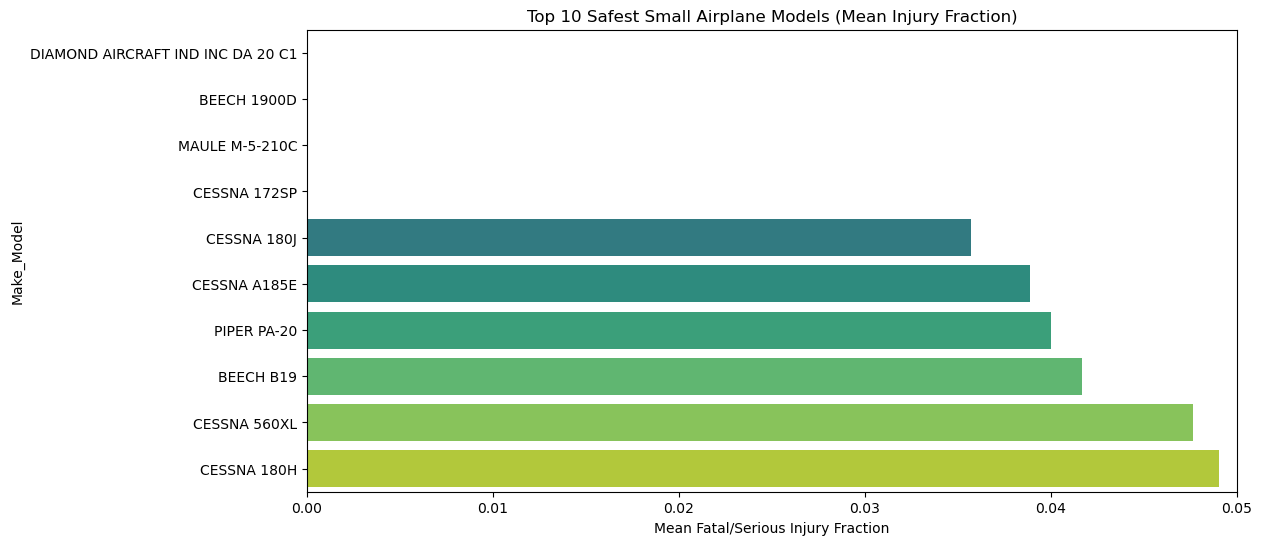

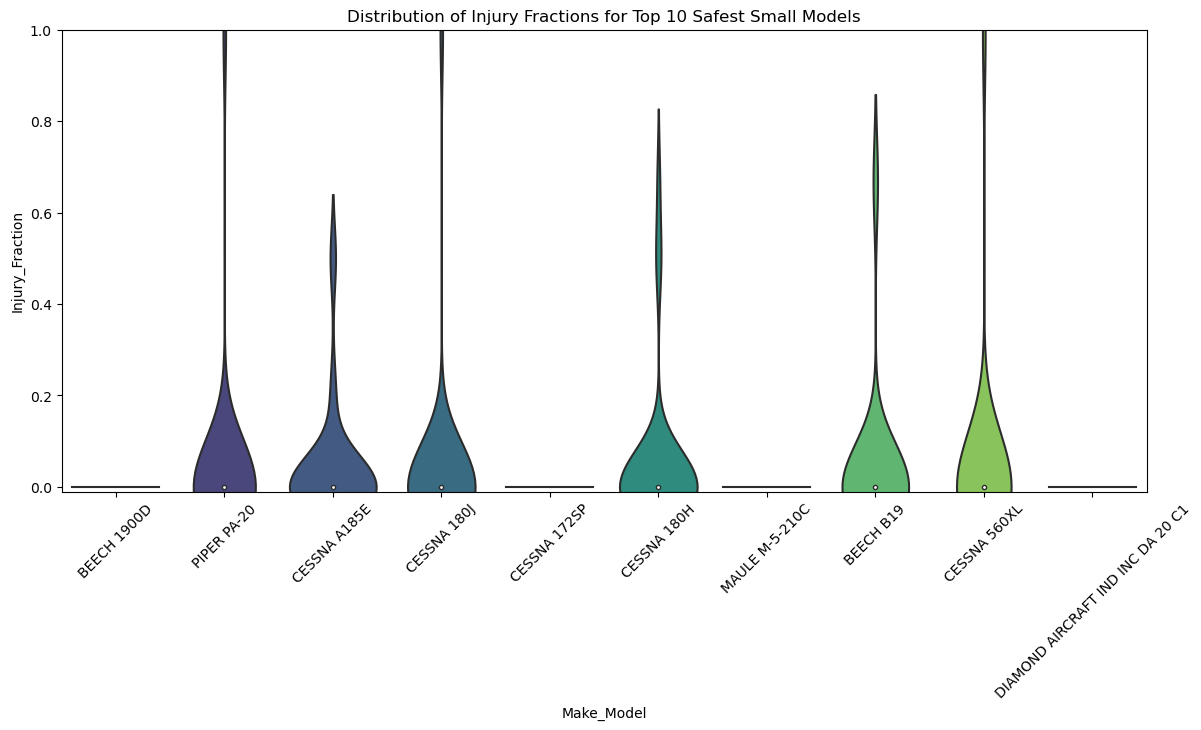

In [10]:
# Isolate the Smaller planes (20 or fewer passengers)
small_types_df = df_types[df_types['Total.Passengers_Est'] <= 20]

# --- FIX: Filter out large commercial jets that were misclassified ---
# We only want makes that are actually known for small planes
small_makes_only = ['CESSNA', 'PIPER', 'MAULE', 'BEECH', 'MOONEY', 'CIRRUS DESIGN CORP', 'STINSON', 'AERONCA', 'BELLANCA', 'DIAMOND AIRCRAFT IND INC']
small_types_df = small_types_df[small_types_df['Make'].isin(small_makes_only)]

# Get the mean injury fraction for small models and keep the 10 lowest
small_model_safety = small_types_df.groupby('Make_Model')['Injury_Fraction'].mean().sort_values().head(10)

# 1. Plot the mean fraction (Bar Plot)
plt.figure(figsize=(12, 6))
sns.barplot(x=small_model_safety.values, y=small_model_safety.index, palette='viridis')
plt.title('Top 10 Safest Small Airplane Models (Mean Injury Fraction)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.xlim(0, 0.05) # Keep the zoom so we can see the small differences
plt.show()

# 2. Provide a distributional plot (Violin Plot)
plt.figure(figsize=(14, 6))
top_small_models = small_model_safety.index
sns.violinplot(data=small_types_df[small_types_df['Make_Model'].isin(top_small_models)], 
               x='Make_Model', y='Injury_Fraction', palette='viridis')
plt.title('Distribution of Injury Fractions for Top 10 Safest Small Models')
plt.xticks(rotation=45)
plt.ylim(-0.01, 1.0) 
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Discussion of Specific Airplane Types

When analyzing specific airplane models (filtering for those with at least 10 recorded accidents), clear winners emerge in both size categories:

*Small Airplane Models:
 Models like the *Cessna 180J, **Piper PA-20, and **Beech B19* show incredibly low mean injury fractions. 
The distribution plots reveal that the vast majority of accidents for these specific models result in near-zero serious/fatal injuries. This makes them highly attractive for an insurer looking to cover small, general aviation aircraft.

*Large Airplane Models:
Commercial heavyweights like the *Boeing 737 series, **Boeing 777, and **Airbus A319/A330* dominate the top 15 safest large models.
 The mean injury fraction for these large models is exceptionally close to zero. The stripplot confirms that while accidents do happen, the likelihood of a high casualty rate is remarkably low, proving the effectiveness of modern commercial aviation safety regulations.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

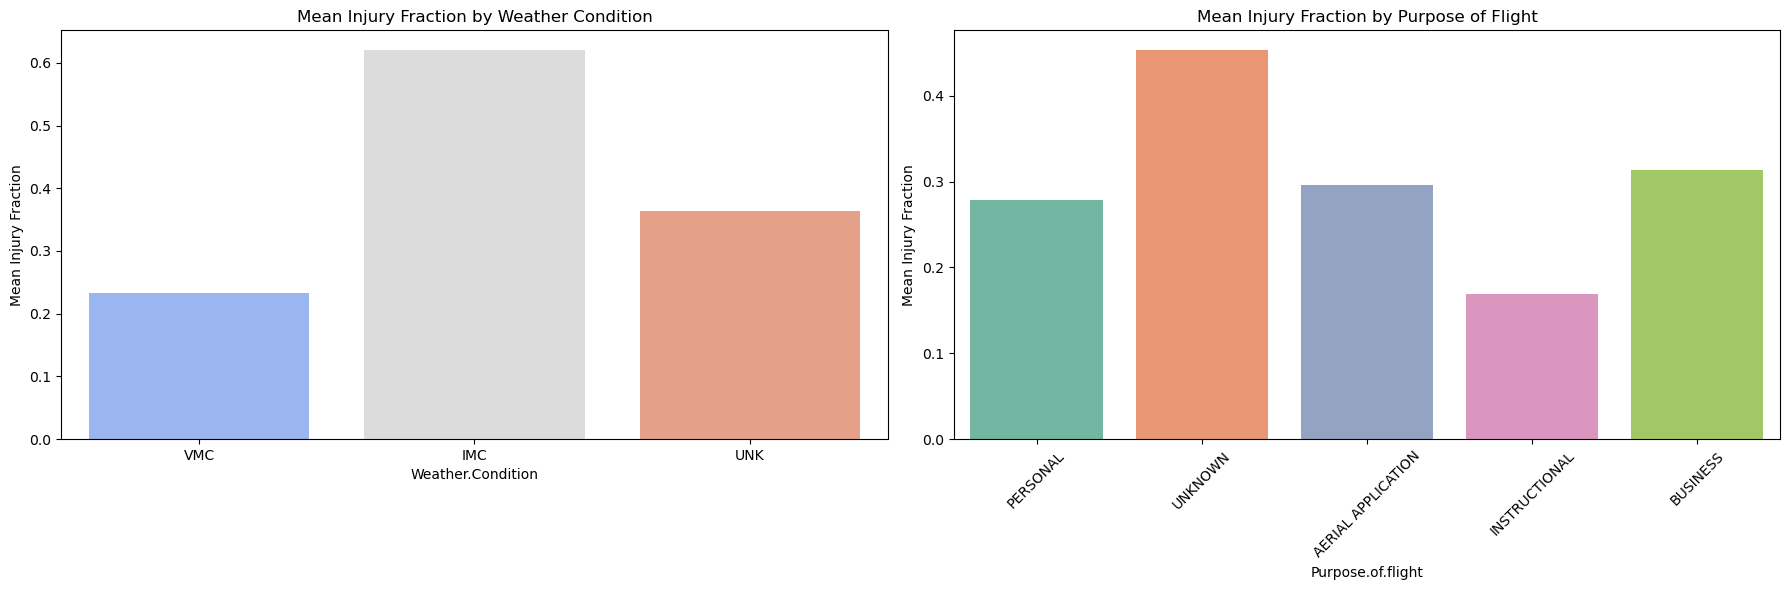

In [11]:
# We will analyze Weather.Condition and Purpose.of.flight

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Weather Condition vs Injury Fraction
sns.barplot(data=df, x='Weather.Condition', y='Injury_Fraction', palette='coolwarm', ax=axes[0], errorbar=None)
axes[0].set_title('Mean Injury Fraction by Weather Condition')
axes[0].set_ylabel('Mean Injury Fraction')

# 2. Purpose of Flight vs Injury Fraction (Top 5 purposes by count to avoid clutter)
top_purposes = df['Purpose.of.flight'].value_counts().head(5).index
sns.barplot(data=df[df['Purpose.of.flight'].isin(top_purposes)], 
            x='Purpose.of.flight', y='Injury_Fraction', palette='Set2', ax=axes[1], errorbar=None)
axes[1].set_title('Mean Injury Fraction by Purpose of Flight')
axes[1].set_ylabel('Mean Injury Fraction')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Discussion of Other Safety Factors

Based on the analysis of weather conditions and the purpose of the flight, we can draw the following conclusions:

1. Weather Condition:
 The charts clearly show that accidents occurring in *IMC (Instrument Meteorological Conditions)* result in a significantly higher mean injury fraction (around 0.6) compared to those in *VMC (Visual Meteorological Conditions)* which is roughly 0.23. 
 *Interpretation:* IMC means poor visibility (clouds, fog, heavy rain). Pilots rely entirely on instruments, and spatial disorientation is more likely, leading to more severe crashes. VMC accidents often happen with better visibility, allowing for better outcomes.

2. Purpose of Flight:
 The phase of flight heavily impacts the injury severity. *Personal* flights show a notably higher mean injury fraction (around 0.28) compared to *Instructional* flights (around 0.16).
 *Interpretation:* Personal flights often involve smaller aircraft, varying pilot experience levels, and flying in more challenging conditions. Instructional flights usually happen in controlled environments with a flight instructor on board, leading to safer outcomes when accidents occur.